# Fig. 4 · L2 静态平衡性质

**主张**：模型普遍"学对了坐在哪里（V0），没学对有多硬（B0）"。立方相 EOS 在五种空位排布上逐 seed 配对，误差与 DFT 自身的跨排布散布对比。

- **a** 六方相固定体积离子弛豫 EOS（各自扣最小值）。专用势训练集含六方相，该参考对它们是被污染的。
- **b** 立方相（seed 1）EOS。
- **c** 立方相 V0 误差 vs B0 误差，灰框 = DFT 跨排布散布（V0 0.19%，B0 5.30%）。
- **d** 立方相 V0 误差；**e** 立方相 B0 误差（负 = 偏软）；**f** 六方相 B0 误差（空心 = 被污染）。

In [1]:
import sys, json, glob
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image as NotebookImage, display
sys.path.insert(0, str(Path.cwd()))
from style import *

In [2]:
# ---------------- 字体设置 / fonts（唯一定义字号的地方） ----------------
FS = use_paper_fonts()          # PAPER_FONTS lives in style.py
FS_TITLE, FS_LABEL, FS_TICK   = FS['title'], FS['label'], FS['tick']
FS_LEGEND, FS_ANNOT, FS_PANEL = FS['legend'], FS['annot'], FS['panel']
FS_CBLABEL, FS_CBTICK         = FS['cbar_label'], FS['cbar_tick']

In [3]:
NAME = "fig4_L2"
OUT = FIG_ROOT / "panels" / NAME
PREVIEW_SCALE = 0.25          # notebook 内预览缩放；不影响导出
LEFT, RIGHT, WS = 0.135, 0.985, 0.42    # copied verbatim by every 3-column figure
CH, G, BM, TM = 1.45, 0.62, 0.36, 0.24  # row height, row gap, bottom/top margin (in)
ROWS = 2
LETTERS = "abcdef"

def make_layout():
    H = BM + ROWS * CH + (ROWS - 1) * G + TM
    fig = plt.figure(figsize=(W2, H))
    gs = fig.add_gridspec(ROWS, 3, left=LEFT, right=RIGHT, bottom=BM / H, top=1 - TM / H,
                          wspace=WS, hspace=G / CH)
    slots = {}
    for i, letter in enumerate(LETTERS):
        r, c = divmod(i, 3)
        slots[letter] = gs[r, c]
    return fig, Slots(slots)

def panel_run(letter, draw):
    fig, slots = make_layout()
    draw(fig, slots[letter])
    group = {"axes": list(fig.axes), "texts": list(fig.texts)}
    boxes = save_matched_panels(fig, {letter: group}, OUT); plt.close(fig)
    display(NotebookImage(filename=str(OUT / f"{letter}.png"), width=int(boxes[letter].width * 600 * PREVIEW_SCALE)))

In [4]:
def model_rows(ax, show_labels):
    """Shared y axis for the nine-model summary panels: universal on top, specialised below."""
    y = {k: i for i, k in enumerate(SHOWCASE)}
    ax.set_ylim(len(SHOWCASE) - 0.4, -0.6)
    ax.set_yticks(range(len(SHOWCASE)))
    ax.set_yticklabels([lab(k) for k in SHOWCASE] if show_labels else [])
    ax.axhline(len(UNIVERSAL) - 0.5, color="#BBBBBB", lw=0.4, ls=(0, (2, 2)))
    ax.tick_params(axis="y", length=0)
    return y

def contaminated(model):
    from mlipeval.ranking import contaminated_metric_ids
    return set(contaminated_metric_ids([model]))

In [5]:
L2 = {k: results(k, "L2_*.json") for k in SHOWCASE}
def eos(k, name):
    z = npz(k, name)
    v = z["volumes"] / float(z["n_atoms"]); e = z["energies"] / float(z["n_atoms"])
    return v, (e - e.min()) * 1000

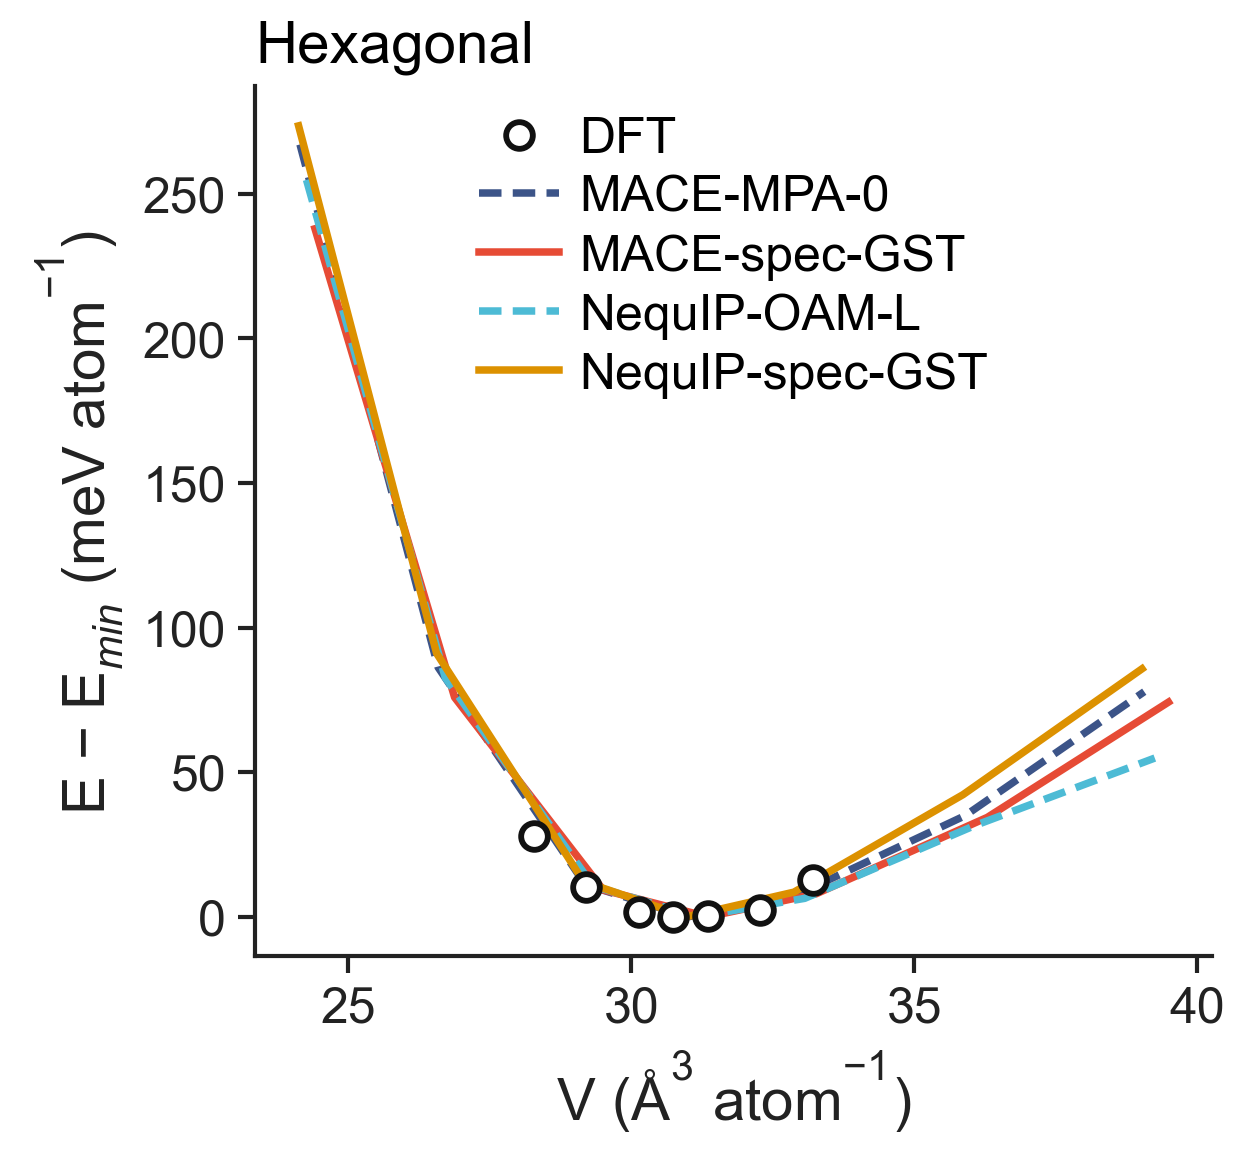

In [6]:
# ---------------- 本面板配色 ----------------
Ca_DFT = "#111111"
# --------------------------------------------
def eos_panel(fig, spec, tag, title, legend):
    ax = fig.add_subplot(spec)
    v, e = eos("mace_mpa0", f"l2_eos_{tag}_dft.npz")
    ax.plot(v, e, "o", color=Ca_DFT, ms=3.2, mfc="white", mew=0.7, label="DFT", zorder=3)
    for k in FOCUS:
        v, e = eos(k, f"l2_eos_{tag}_mlip.npz")
        ls = "-" if MODELS[k][3] == "specialised" else (0, (3, 1.5))
        ax.plot(v, e, color=col(k), ls=ls, lw=0.9, label=lab(k))
    ax.set_xlabel("V (Å$^3$ atom$^{-1}$)"); ax.set_ylabel("E − E$_{min}$ (meV atom$^{-1}$)")
    ax.set_title(title, loc="left")
    if legend: ax.legend(loc="upper center")
    return ax
def draw_a(fig, spec):
    return eos_panel(fig, spec, "hex", "Hexagonal", True)
panel_run("a", draw_a)

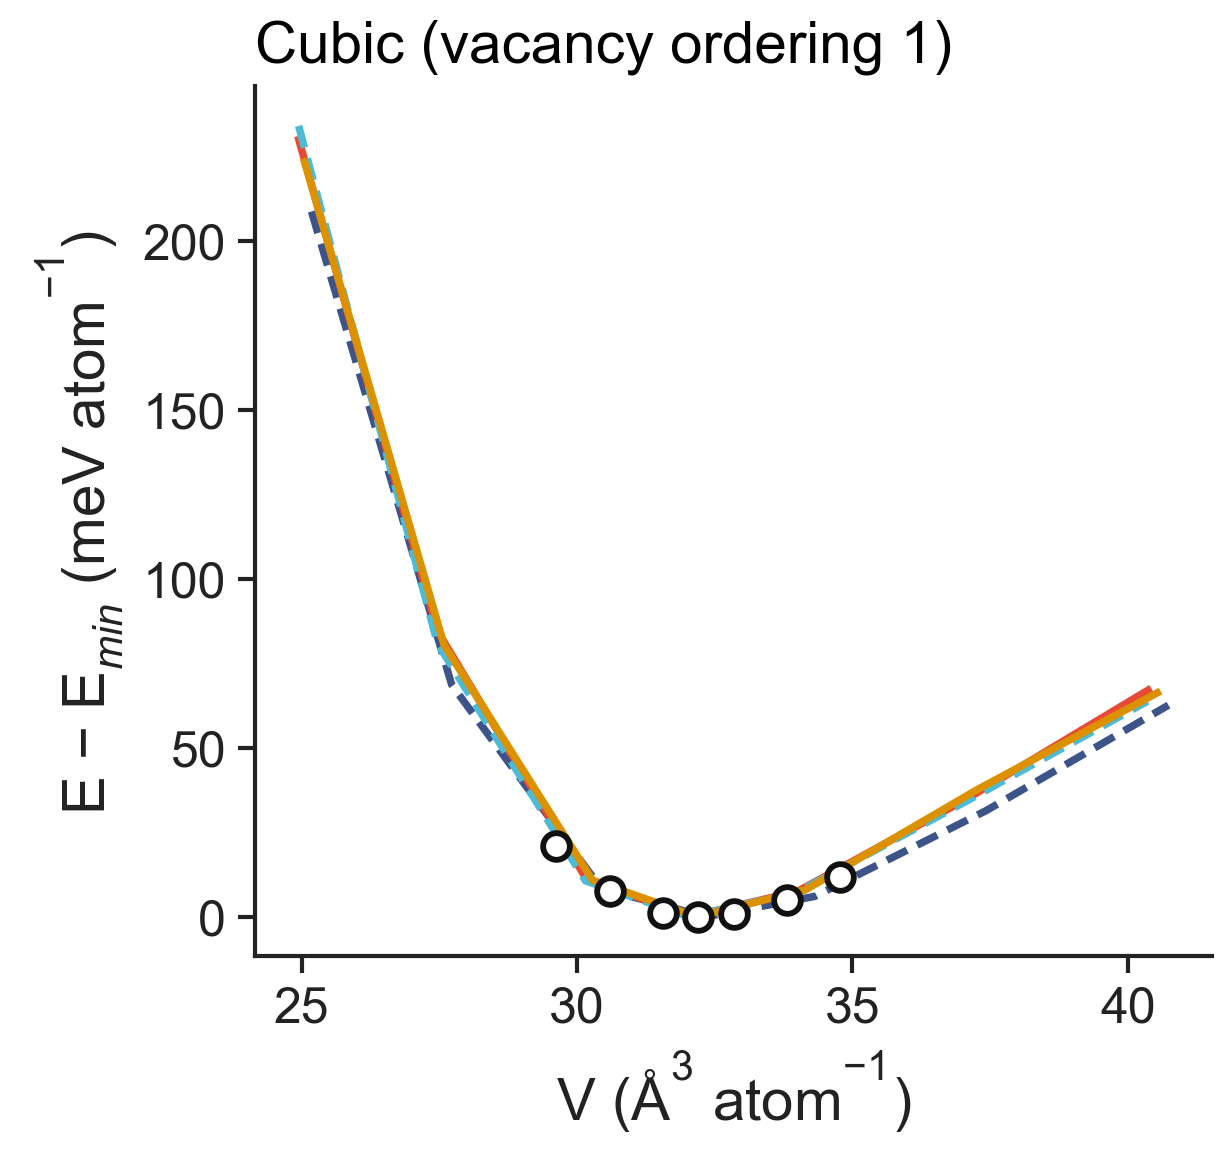

In [7]:
def draw_b(fig, spec):
    return eos_panel(fig, spec, "cubic_s01", "Cubic (vacancy ordering 1)", False)
panel_run("b", draw_b)

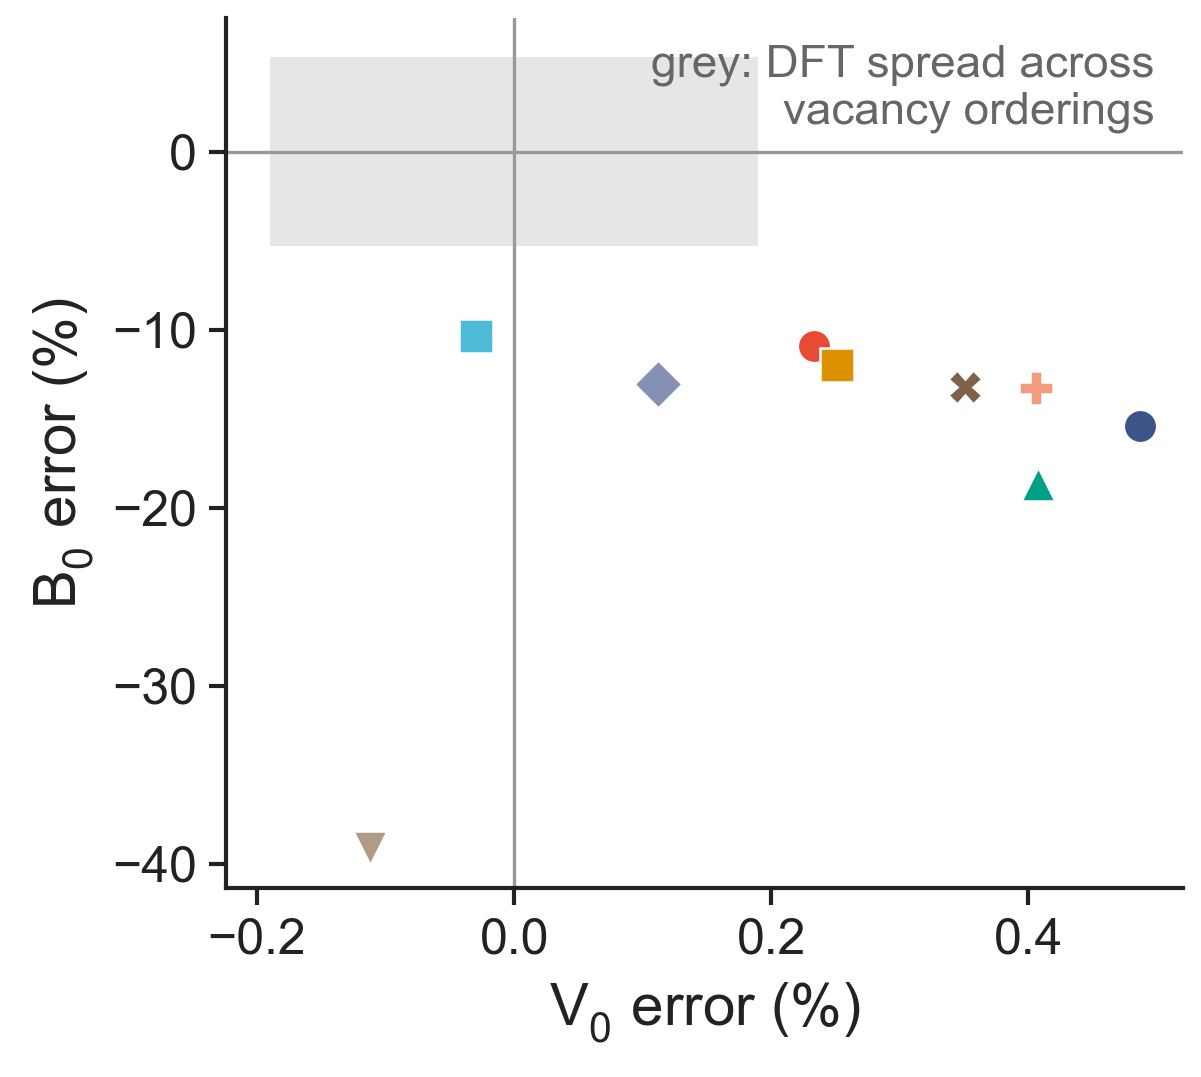

In [8]:
# ---------------- 本面板配色 ----------------
Cc_BOX = "#E6E6E6"
# --------------------------------------------
def draw_c(fig, spec):
    ax = fig.add_subplot(spec)
    from matplotlib.patches import Rectangle
    ax.add_patch(Rectangle((-0.19, -5.30), 0.38, 10.6, color=Cc_BOX, lw=0, zorder=0))
    ax.axhline(0, color="#999999", lw=0.4); ax.axvline(0, color="#999999", lw=0.4)
    for k in SHOWCASE:
        x = L2[k]["L2.eos.cubic.V0_error"]["value"]; y = L2[k]["L2.eos.cubic.B0_error"]["value"]
        ax.plot(x, y, mkr(k), color=col(k), ms=4, mec="white", mew=0.3)
    ax.set_xlabel("V$_0$ error (%)"); ax.set_ylabel("B$_0$ error (%)")
    ax.text(0.97, 0.97, "grey: DFT spread across\nvacancy orderings", transform=ax.transAxes, ha="right", va="top", fontsize=FS_ANNOT - 0.5, color="#666666")
    return ax
panel_run("c", draw_c)

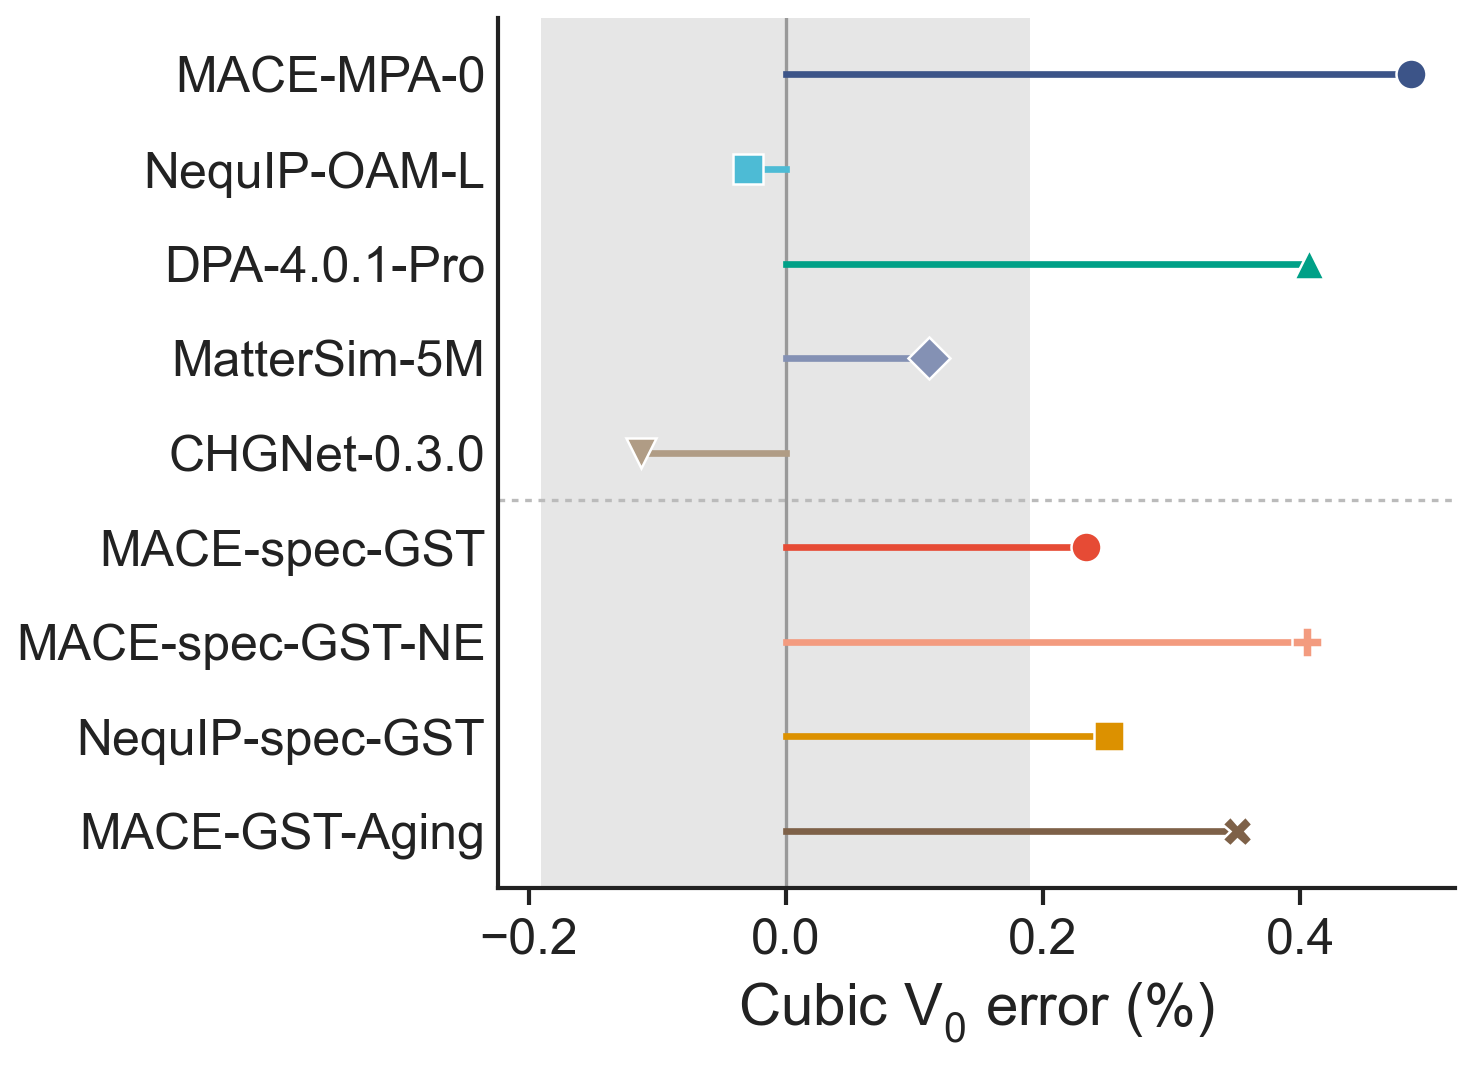

In [9]:
def signed_dots(fig, spec, metric, xlabel, show_labels, spread=None):
    ax = fig.add_subplot(spec)
    y = model_rows(ax, show_labels)
    if spread: ax.axvspan(-spread, spread, color="#E6E6E6", lw=0, zorder=0)
    ax.axvline(0, color="#999999", lw=0.4)
    for k in SHOWCASE:
        r = L2[k].get(metric)
        if r is None: continue
        dirty = metric in contaminated(k)
        ax.plot([0, r["value"]], [y[k]] * 2, color=col(k), lw=0.8)
        ax.plot(r["value"], y[k], mkr(k), color=col(k), ms=3.6, mfc="white" if dirty else col(k), mew=0.7 if dirty else 0.3,
                mec=col(k) if dirty else "white")
        sd = (r.get("uncertainty") or None)
    ax.set_xlabel(xlabel)
    return ax
def draw_d(fig, spec):
    return signed_dots(fig, spec, "L2.eos.cubic.V0_error", "Cubic V$_0$ error (%)", True, spread=0.19)
panel_run("d", draw_d)

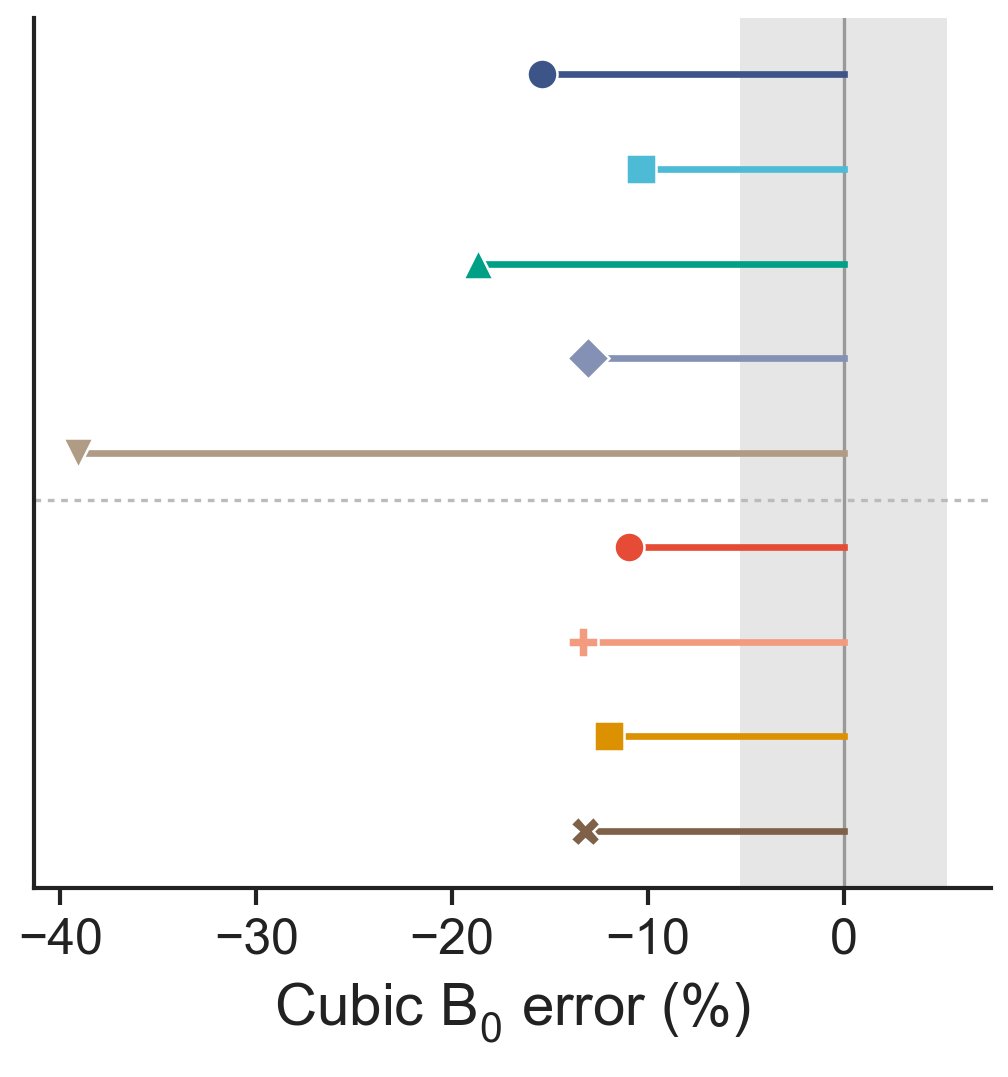

In [10]:
def draw_e(fig, spec):
    return signed_dots(fig, spec, "L2.eos.cubic.B0_error", "Cubic B$_0$ error (%)", False, spread=5.30)
panel_run("e", draw_e)

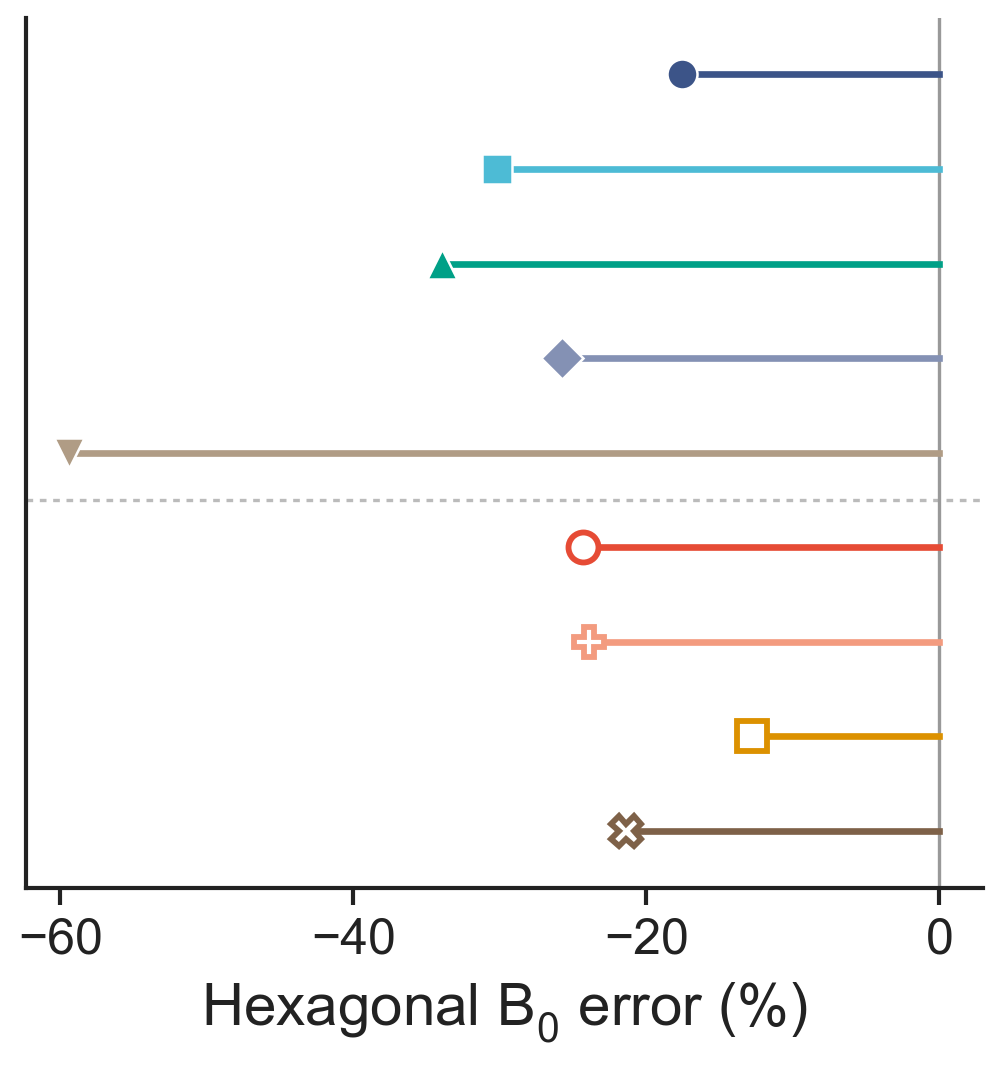

In [11]:
def draw_f(fig, spec):
    return signed_dots(fig, spec, "L2.eos.hex.B0_error", "Hexagonal B$_0$ error (%)", False)
panel_run("f", draw_f)

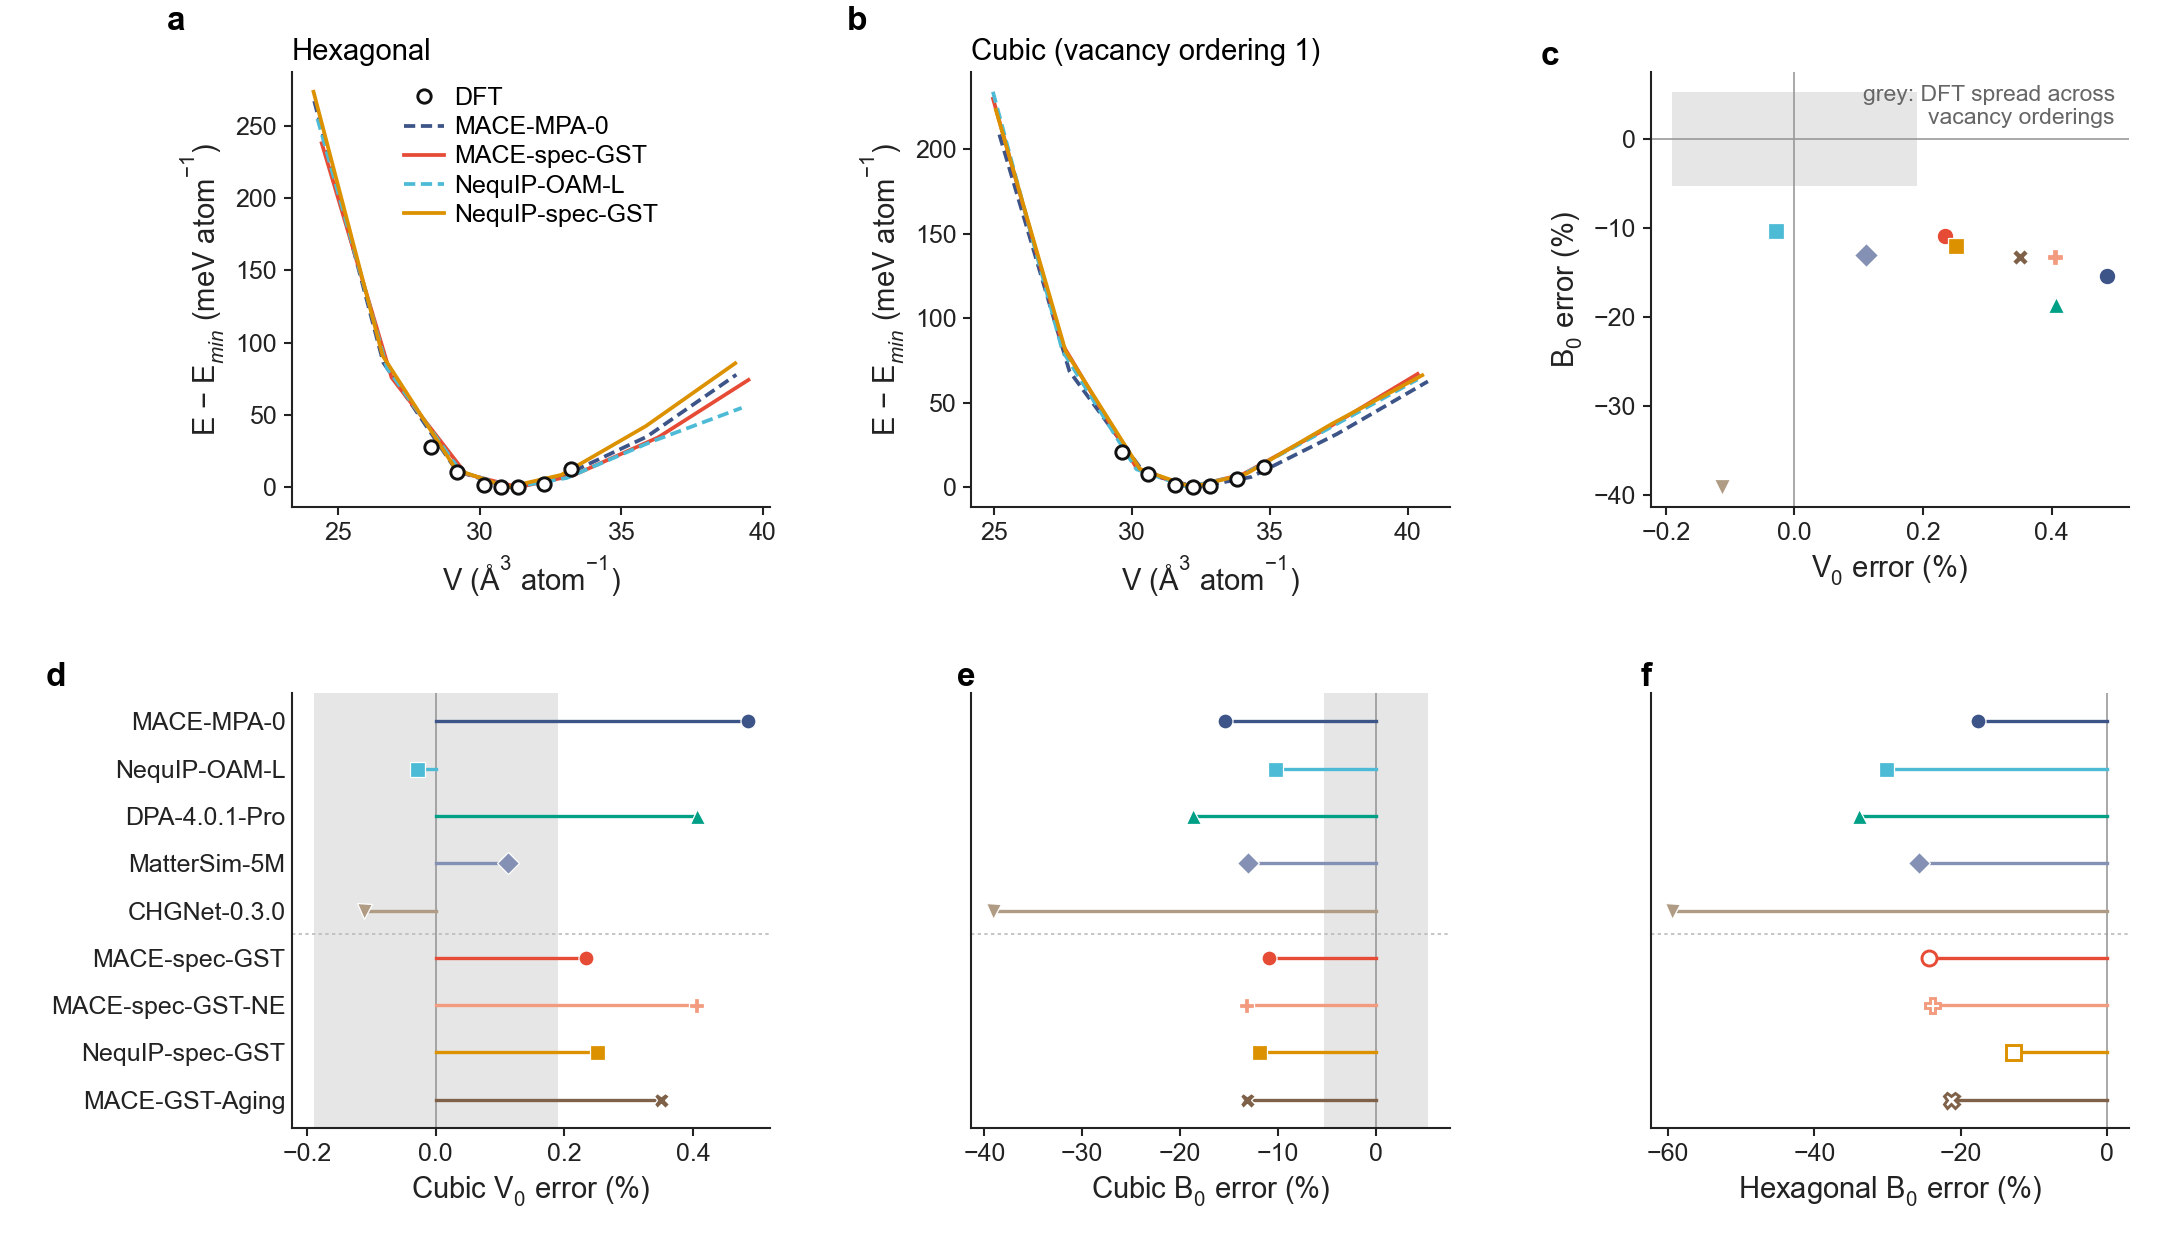

In [12]:
fig, slots = make_layout()
DRAW = {l: globals()[f"draw_{l}"] for l in LETTERS}
main_axes = {}
for l in LETTERS:
    n0 = len(fig.axes)
    ax = DRAW[l](fig, slots[l])
    main_axes[l] = ax
for l in LETTERS:
    mark(fig, main_axes[l], l, FS_PANEL)
png = export(fig, "fig4_L2")
groups = {}
plt.close(fig)
display(NotebookImage(filename=str(png), width=900))